<a href="https://colab.research.google.com/github/Palak-mukheja/LeetCode/blob/main/UNC503_A2_1024150040_Palak.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UNC503 AIML Laboratory | Assignment 2
## Intelligent Campus Route Planner (DFS, BFS, UCS and A*)

| | |
|---|---|
| **Name** | palak mukheja |
| **Roll No** | 1024150040 |
| **Last digit used for closure** | **4** |
| **Assigned road closure** | cell **(2, 10)** replaced with `#` (digit 4 or 9 in Section 2.7) |
| **Institute** | Thapar Institute of Engineering and Technology, Patiala |

### AI-assistance declaration
>  *"I used Claude (Anthropic) to help draft and explain the search code and notebook structure. I read every function, traced DFS/BFS/UCS/A* by hand on MINI_MAP, ran all cells in a fresh runtime, and checked each result with `validate_path` and independent cost recomputation. I can explain every line."*

## 2. Objective and problem formulation
In Assignment 1 a human supplied the commands. Here the robot must **choose its own route** from `S` to `G` on a weighted campus grid using four graph-search algorithms implemented from scratch: **DFS, BFS, Uniform-Cost Search and A\***. They are compared on identical maps, action order, costs and metric definitions, then the route is re-planned after my assigned road closure.

### Task 1A - Search problem for `CAMPUS_MAP`
| Component | Definition for this assignment | Python representation |
|---|---|---|
| **State** | The robot's current `(row, column)` cell | tuple, e.g. `(2, 5)` |
| **Initial state** | The unique cell containing `S`; here `(0, 0)` | `find_symbol(grid, 'S')` |
| **Actions** | NORTH, EAST, SOUTH, WEST (this order everywhere) | `ACTION_ORDER`, keys of `MOVE_DELTAS` |
| **Successor function** | Every adjacent cell inside the grid that is not `#`, with the cost of entering it | `get_successors(grid, state)` |
| **Goal test** | The selected (popped) state equals the cell containing `G`; here `(0, 11)` | `state == goal` |
| **Step cost** | Terrain cost of the **destination** cell: `.`=1, `G`=1, `C`=2, `M`=3 (start `S`=0) | `TERRAIN_COSTS[grid[r][c]]` |
| **Path cost g(n)** | Sum of destination-cell costs from `S` to `n`; the start contributes 0 | `best_g[state]` |
| **Solution** | Ordered list of states from S to G and the list of actions between them | `path`, `actions` |

## 3. Imports and configuration
One import cell, then the constants and maps **exactly as supplied** (Task 1B). Only permitted libraries are used: `collections`, `heapq`, `itertools`, `math`, `statistics`, `time`, `copy`, NumPy, pandas and Matplotlib.

In [ ]:
import copy
from collections import deque
from heapq import heappush, heappop
from itertools import count
from math import inf
from statistics import median
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

In [ ]:
ACTION_ORDER = ['NORTH', 'EAST', 'SOUTH', 'WEST']
MOVE_DELTAS = {'NORTH': (-1, 0), 'EAST': (0, 1), 'SOUTH': (1, 0), 'WEST': (0, -1)}
TERRAIN_COSTS = {'S': 0, 'G': 1, '.': 1, 'M': 3, 'C': 2}
ALLOWED_SYMBOLS = {'S', 'G', '.', 'M', 'C', '#'}

CAMPUS_MAP = [
    list('SMMMMM.....G'),
    list('.##########.'),
    list('............'),
    list('.###.###.##.'),
    list('....C.......'),
    list('###.#####.##'),
    list('............'),
    list('.##########.'),
    list('............'),
]
MULTIPLE_ROUTE_MAP = [
    list('S...#....G'),
    list('.#..#..#..'),
    list('.#..#..#..'),
    list('..........'),
    list('..#...#...'),
    list('..#####...'),
    list('..........'),
]
NO_SOLUTION_MAP = [
    list('S..#..G'),
    list('...#...'),
    list('...#...'),
    list('...#...'),
    list('...#...'),
]
MINI_MAP = [
    list('SMMMG'),
    list('.###.'),
    list('.....'),
]

**Task 1D** - Dimensions, start and goal of each supplied map are *computed*, not hardcoded.

## 4. Environment utilities (Tasks 1C and 2)
The environment code knows nothing about search algorithms. This keeps **environment**, **search**, **measurement** and **visualisation** separate.

* `validate_grid` - rejects empty, non-rectangular, unknown-symbol, or wrong S/G-count grids.
* `find_symbol` - returns a coordinate only when the symbol occurs exactly once.
* `inside_grid` - boundary check that rejects negative indices (Python would otherwise wrap them).
* `terrain_cost` - cost of **entering** a cell; raises `ValueError` for `#` or outside cells so mistakes are loud.

In [ ]:
def validate_grid(grid):
    errors = []
    if not grid or all(len(row) == 0 for row in grid):
        return {'valid': False, 'errors': ['EMPTY_GRID']}
    if len({len(row) for row in grid}) > 1:
        errors.append('NON_RECTANGULAR')
    s_count = g_count = 0
    bad = False
    for row in grid:
        for cell in row:
            if cell not in ALLOWED_SYMBOLS:
                bad = True
            elif cell == 'S':
                s_count += 1
            elif cell == 'G':
                g_count += 1
    if bad:
        errors.append('INVALID_SYMBOL')
    if s_count != 1:
        errors.append('START_COUNT')
    if g_count != 1:
        errors.append('GOAL_COUNT')
    return {'valid': not errors, 'errors': errors}


def find_symbol(grid, symbol):
    matches = [(r, c) for r, row in enumerate(grid) for c, cell in enumerate(row) if cell == symbol]
    return matches[0] if len(matches) == 1 else None


def inside_grid(grid, state):
    row, col = state
    if row < 0 or col < 0:
        return False
    return row < len(grid) and col < len(grid[row])


def terrain_cost(grid, state):
    if not inside_grid(grid, state):
        raise ValueError(f'{state} is outside the grid')
    symbol = grid[state[0]][state[1]]
    if symbol == '#':
        raise ValueError(f'{state} is an obstacle and cannot be entered')
    return TERRAIN_COSTS[symbol]

In [ ]:
SUPPLIED_MAPS = {'MINI_MAP': MINI_MAP, 'CAMPUS_MAP': CAMPUS_MAP,
                 'MULTIPLE_ROUTE_MAP': MULTIPLE_ROUTE_MAP, 'NO_SOLUTION_MAP': NO_SOLUTION_MAP}

# Task 1D: every value below is computed by the utilities
for name, grid in SUPPLIED_MAPS.items():
    check = validate_grid(grid)
    print(f"{name:20} valid={check['valid']} errors={check['errors']} "
          f"size={len(grid)}x{len(grid[0])} start={find_symbol(grid, 'S')} goal={find_symbol(grid, 'G')}")

MINI_MAP             valid=True errors=[] size=3x5 start=(0, 0) goal=(0, 4)
CAMPUS_MAP           valid=True errors=[] size=9x12 start=(0, 0) goal=(0, 11)
MULTIPLE_ROUTE_MAP   valid=True errors=[] size=7x10 start=(0, 0) goal=(0, 9)
NO_SOLUTION_MAP      valid=True errors=[] size=5x7 start=(0, 0) goal=(0, 6)


**Task 2A / 2B / 2C - successors, path reconstruction, cost and path validation.**
* `get_successors` loops over `ACTION_ORDER` (never over the dictionary) so every algorithm sees neighbours in the same order. It returns `(action, next_state, step_cost)`.
* `reconstruct_path` walks parent links from the goal back to the start, then reverses both lists, so `len(path) == len(actions) + 1`.
* `compute_path_cost` sums the cost of every cell **entered** (`path[1:]`), so the start is free.
* `validate_path` re-checks a route independently of the search that produced it and gives a descriptive message for every kind of fault.

In [ ]:
def get_successors(grid, state):
    row, col = state
    successors = []
    for action in ACTION_ORDER:
        d_row, d_col = MOVE_DELTAS[action]
        nxt = (row + d_row, col + d_col)
        if inside_grid(grid, nxt) and grid[nxt[0]][nxt[1]] != '#':
            successors.append((action, nxt, terrain_cost(grid, nxt)))
    return successors


def reconstruct_path(parent, action_from_parent, goal):
    states_reversed, actions_reversed = [], []
    current = goal
    while current is not None:
        states_reversed.append(current)
        action = action_from_parent.get(current)
        if action is not None:
            actions_reversed.append(action)
        current = parent.get(current)
    return states_reversed[::-1], actions_reversed[::-1]


def compute_path_cost(grid, path):
    return sum(terrain_cost(grid, state) for state in path[1:])


def validate_path(grid, path, actions):
    errors = []
    if not path:
        return {'valid': False, 'errors': ['EMPTY_PATH']}
    if len(path) != len(actions) + 1:
        errors.append(f'LENGTH_MISMATCH: {len(path)} states but {len(actions)} actions')
    if path[0] != find_symbol(grid, 'S'):
        errors.append(f'BAD_START: path starts at {path[0]}')
    if path[-1] != find_symbol(grid, 'G'):
        errors.append(f'BAD_GOAL: path ends at {path[-1]}')
    for i, state in enumerate(path):
        if not inside_grid(grid, state):
            errors.append(f'OUT_OF_GRID: {state} at index {i}')
        elif grid[state[0]][state[1]] == '#':
            errors.append(f'ENTERS_OBSTACLE: {state} at index {i}')
    for i in range(len(path) - 1):
        a, b = path[i], path[i + 1]
        d = (b[0] - a[0], b[1] - a[1])
        if abs(d[0]) + abs(d[1]) != 1:
            errors.append(f'NOT_ADJACENT: {a} -> {b}')
        elif i < len(actions) and MOVE_DELTAS.get(actions[i]) != d:
            errors.append(f'ACTION_MISMATCH: step {i + 1} says {actions[i]} but move is {d}')
    return {'valid': not errors, 'errors': errors}

In [ ]:
# Task 2D - quick utility checks on MINI_MAP (formal assertions are in section 6)
print('successors of start (0,0):', get_successors(MINI_MAP, (0, 0)))
print('successors of corner (2,0):', get_successors(MINI_MAP, (2, 0)))
print('successors of obstacle-neighbour (0,3):', get_successors(MINI_MAP, (0, 3)))
print('successors of goal (0,4):', get_successors(MINI_MAP, (0, 4)))

upper = [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4)]
lower = [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (1, 4), (0, 4)]
print('upper route cost:', compute_path_cost(MINI_MAP, upper), '| lower route cost:', compute_path_cost(MINI_MAP, lower))
print(validate_path(MINI_MAP, upper, ['EAST'] * 4))
print(validate_path(MINI_MAP, [(0, 0), (0, 2)], ['EAST']))            # non-adjacent

successors of start (0,0): [('EAST', (0, 1), 3), ('SOUTH', (1, 0), 1)]
successors of corner (2,0): [('NORTH', (1, 0), 1), ('EAST', (2, 1), 1)]
successors of obstacle-neighbour (0,3): [('EAST', (0, 4), 1), ('WEST', (0, 2), 3)]
successors of goal (0,4): [('SOUTH', (1, 4), 1), ('WEST', (0, 3), 3)]
upper route cost: 10 | lower route cost: 8
{'valid': True, 'errors': []}
{'valid': False, 'errors': ['BAD_GOAL: path ends at (0, 2)', 'NOT_ADJACENT: (0, 0) -> (0, 2)']}


**Section 5.4 - predictions before coding (answered, then checked by code below)**
1. `get_successors(MINI_MAP, (0, 0))` in order: `EAST -> (0,1)` cost 3, then `SOUTH -> (1,0)` cost 1 (NORTH and WEST leave the grid).
2. `h((2,0),(0,4)) = |2-0| + |0-4| = 6` and `h((0,3),(0,4)) = 1`.
3. BFS counts *movements*, not terrain cost; the 4-step muddy top route beats the 8-step lower route in depth even though it costs 10 versus 8.
4. If UCS had `best_g[x] = 9` and then generates `x` with `new_g = 6`, it must set `best_g[x] = 6`, update `parent[x]` and `action_from_parent[x]` together, and push a **new** heap entry; the old (9) entry stays in the heap and is skipped later as stale.
5. With `h(n) = 0` for every state, `f = g`, so A\* becomes UCS.

## 5. Search implementations (Tasks 3 to 6)
### Result helpers
`failure_result` and `make_result` build the standard result dictionary so all four algorithms return identical keys. `make_result` computes `path_cost` from the **path** with `compute_path_cost` (not by trusting a running total). I added one extra key, `cost_updates`, to UCS/A\* so Q8 can be answered from data.

In [ ]:
def failure_result(name, nodes_expanded=0, max_frontier_size=0, expansion_order=None, extra=None):
    result = {'algorithm': name, 'goal_reached': False, 'path': [], 'actions': [], 'steps': None,
              'path_cost': None, 'nodes_expanded': nodes_expanded, 'max_frontier_size': max_frontier_size,
              'expansion_order': list(expansion_order or [])}
    result.update(extra or {})
    return result


def make_result(name, grid, parent, action_from_parent, goal, nodes_expanded, max_frontier_size,
                expansion_order, extra=None):
    path, actions = reconstruct_path(parent, action_from_parent, goal)
    result = {'algorithm': name, 'goal_reached': True, 'path': path, 'actions': actions,
              'steps': len(actions), 'path_cost': compute_path_cost(grid, path),
              'nodes_expanded': nodes_expanded, 'max_frontier_size': max_frontier_size,
              'expansion_order': list(expansion_order)}
    result.update(extra or {})
    return result

### Task 3 - Depth-First Search (list used as a stack)
* A state is marked **discovered when pushed**, not when popped, so it can never sit in the stack twice.
* Successors are pushed in **reverse** `ACTION_ORDER`, so NORTH (first in the order) is popped first.
* Goal test happens **after popping**; `nodes_expanded` increases only for non-goal selected states.
* `max_frontier` is updated after every push.

In [ ]:
def depth_first_search(grid):
    if not validate_grid(grid)['valid']:
        return failure_result('DFS')
    start, goal = find_symbol(grid, 'S'), find_symbol(grid, 'G')
    stack = [start]
    discovered = {start}
    parent, action_from_parent = {start: None}, {start: None}
    nodes_expanded, max_frontier, order = 0, 1, []
    while stack:
        state = stack.pop()
        if state == goal:
            return make_result('DFS', grid, parent, action_from_parent, goal, nodes_expanded, max_frontier, order)
        nodes_expanded += 1
        order.append(state)
        for action, nxt, _ in reversed(get_successors(grid, state)):
            if nxt not in discovered:
                discovered.add(nxt)
                parent[nxt], action_from_parent[nxt] = state, action
                stack.append(nxt)
                max_frontier = max(max_frontier, len(stack))
    return failure_result('DFS', nodes_expanded, max_frontier, order)

**3E - Why DFS is not "shortest" or "cheapest" (about 100 words).**
DFS always dives into the most recently added neighbour and stops at the first time it pops the goal. It never compares alternative routes, so nothing about its stopping rule relates to movements or terrain cost. A good-looking result on one map is a side effect of the action order and the map layout: DFS happens to follow the top corridor on CAMPUS_MAP, which has the fewest steps but the highest cost. A different action order or map could send it down a long, expensive detour. Because there is no optimality guarantee, DFS output must be judged against BFS (steps) and UCS (cost).

### Task 4 - Breadth-First Search (`deque` used as a queue)
Same environment functions, goal-test location, metrics and action order as DFS; only the frontier changes: `append` at the back, `popleft` from the front (never `list.pop(0)`). A state is discovered when it is **added** to the queue.

In [ ]:
def breadth_first_search(grid):
    if not validate_grid(grid)['valid']:
        return failure_result('BFS')
    start, goal = find_symbol(grid, 'S'), find_symbol(grid, 'G')
    queue = deque([start])
    discovered = {start}
    parent, action_from_parent = {start: None}, {start: None}
    nodes_expanded, max_frontier, order = 0, 1, []
    while queue:
        state = queue.popleft()
        if state == goal:
            return make_result('BFS', grid, parent, action_from_parent, goal, nodes_expanded, max_frontier, order)
        nodes_expanded += 1
        order.append(state)
        for action, nxt, _ in get_successors(grid, state):
            if nxt not in discovered:
                discovered.add(nxt)
                parent[nxt], action_from_parent[nxt] = state, action
                queue.append(nxt)
                max_frontier = max(max_frontier, len(queue))
    return failure_result('BFS', nodes_expanded, max_frontier, order)

**4E - What BFS guarantees (about 100 words).**
BFS expands states in order of depth, so the first time it reaches G it has used the fewest possible movements. That is its objective, and it achieves it on every map. It does **not** look at terrain cost: when costs vary, a route with fewer steps can cross muddy or crowded cells and cost more than a longer route. On CAMPUS_MAP it returns an 11-step route costing 21, while the cheapest route needs 15 steps and costs 15. BFS is therefore correct for "fewest movements" and wrong for "least terrain cost", unless every cell costs the same.

### Task 5 - Uniform-Cost Search (`heapq` ordered by g)
Heap entry: `(priority, tie_breaker, state, popped_g)`. The `itertools.count` tie-breaker makes equal priorities resolve by insertion order and avoids comparing states. Rules implemented exactly as specified:
1. `best_g[start] = 0`.
2. A successor is accepted only if `new_g < best_g.get(next, inf)`; then `best_g`, `parent` and `action_from_parent` are updated **together**, and a new entry is pushed.
3. After popping, if `popped_g != best_g[state]` the entry is **stale** and skipped without counting an expansion.
4. The goal test is applied only after the best valid entry is popped.

In [ ]:
def uniform_cost_search(grid):
    if not validate_grid(grid)['valid']:
        return failure_result('UCS', extra={'cost_updates': 0})
    start, goal = find_symbol(grid, 'S'), find_symbol(grid, 'G')
    tie = count()
    frontier = []
    heappush(frontier, (0, next(tie), start, 0))
    best_g = {start: 0}
    parent, action_from_parent = {start: None}, {start: None}
    nodes_expanded, max_frontier, order, cost_updates = 0, 1, [], 0
    while frontier:
        priority, _, state, popped_g = heappop(frontier)
        if popped_g != best_g.get(state):
            continue
        if state == goal:
            return make_result('UCS', grid, parent, action_from_parent, goal, nodes_expanded, max_frontier,
                               order, {'cost_updates': cost_updates})
        nodes_expanded += 1
        order.append(state)
        for action, nxt, step_cost in get_successors(grid, state):
            new_g = popped_g + step_cost
            old_g = best_g.get(nxt, inf)
            if new_g < old_g:
                if old_g != inf:
                    cost_updates += 1
                best_g[nxt] = new_g
                parent[nxt], action_from_parent[nxt] = state, action
                heappush(frontier, (new_g, next(tie), nxt, new_g))
                max_frontier = max(max_frontier, len(frontier))
    return failure_result('UCS', nodes_expanded, max_frontier, order, {'cost_updates': cost_updates})

**5F - Why a permanent "seen once, ignore forever" set can give wrong answers in cost-sensitive search.**
A state's first discovery is not necessarily its cheapest: it may be reached first through an expensive route (for example the muddy corridor) while a cheaper route is still waiting in the frontier. If the algorithm marks the state seen and ignores later arrivals, it keeps the expensive parent and `g`, and every route built through that state inherits the extra cost. UCS/A\* therefore keep `best_g` and *replace* the record whenever a strictly lower `g` appears. For BFS and DFS a plain seen-set is fine because they do not use costs to choose routes.

### Task 6 - A\* and the Manhattan heuristic
`manhattan_heuristic(state, goal, min_step_cost=1)` is exactly the form in Section 5.3: Manhattan distance times the **minimum** traversable step cost. `a_star_search` is UCS with priority `f = g + h`; the heuristic is passed in as a function (so a zero heuristic can be swapped in for diagnostics).

In [ ]:
def manhattan_heuristic(state, goal, min_step_cost=1):
    row, col = state
    g_row, g_col = goal
    return (abs(row - g_row) + abs(col - g_col)) * min_step_cost


def zero_heuristic(state, goal):
    """Diagnostic heuristic: h = 0 everywhere, which turns A* into UCS."""
    return 0

In [ ]:
def a_star_search(grid, heuristic=manhattan_heuristic):
    if not validate_grid(grid)['valid']:
        return failure_result('A*', extra={'cost_updates': 0})
    start, goal = find_symbol(grid, 'S'), find_symbol(grid, 'G')
    tie = count()
    frontier = []
    heappush(frontier, (heuristic(start, goal), next(tie), start, 0))
    best_g = {start: 0}
    parent, action_from_parent = {start: None}, {start: None}
    nodes_expanded, max_frontier, order, cost_updates = 0, 1, [], 0
    while frontier:
        priority, _, state, popped_g = heappop(frontier)
        if popped_g != best_g.get(state):
            continue
        if state == goal:
            return make_result('A*', grid, parent, action_from_parent, goal, nodes_expanded, max_frontier,
                               order, {'cost_updates': cost_updates})
        nodes_expanded += 1
        order.append(state)
        for action, nxt, step_cost in get_successors(grid, state):
            new_g = popped_g + step_cost
            old_g = best_g.get(nxt, inf)
            if new_g < old_g:
                if old_g != inf:
                    cost_updates += 1
                best_g[nxt] = new_g
                parent[nxt], action_from_parent[nxt] = state, action
                heappush(frontier, (new_g + heuristic(nxt, goal), next(tie), nxt, new_g))
                max_frontier = max(max_frontier, len(frontier))
    return failure_result('A*', nodes_expanded, max_frontier, order, {'cost_updates': cost_updates})

## 6. Assertions and diagnostics (Tasks 2D, 6C, 6D, 6E, 8A)
First the heuristic diagnostics (6C, 6D, 6E), then the full assertion set. Tests finish silently when correct.

### Heuristic checks
**6C** - `h(goal) == 0` and `h >= 0` on every traversable state.
**6D** - consistency check over every legal edge: `h(n) <= step_cost + h(n')`.

> **Honest note about 6D.** The supplied rules charge `0` for entering the start cell `S`. For an edge that *enters* `S` from a neighbour, `h(n) = h(S) + 1` while the edge cost is `0`, so the inequality is violated by exactly 1. These "edges into S" are never used by a useful route (S already has `g = 0`, the minimum possible, so no search will ever accept a path back into it). The checker therefore reports every violation and I assert that **all violations are edges into S and nothing else**; every other edge satisfies the inequality.

In [ ]:
def check_heuristic(grid, heuristic=manhattan_heuristic):
    """Return (goal_zero, non_negative, consistency_violations) for one map."""
    goal = find_symbol(grid, 'G')
    goal_zero = heuristic(goal, goal) == 0
    non_negative = True
    violations = []
    for r, row in enumerate(grid):
        for c, cell in enumerate(row):
            if cell == '#':
                continue
            state = (r, c)
            if heuristic(state, goal) < 0:
                non_negative = False
            for action, nxt, step_cost in get_successors(grid, state):
                if heuristic(state, goal) > step_cost + heuristic(nxt, goal):
                    violations.append((state, nxt, step_cost))
    return goal_zero, non_negative, violations


for name, grid in SUPPLIED_MAPS.items():
    goal_zero, non_negative, violations = check_heuristic(grid)
    start = find_symbol(grid, 'S')
    only_into_start = all(nxt == start for _, nxt, _ in violations)
    print(f'{name:20} h(goal)=0: {goal_zero} | h>=0: {non_negative} | '
          f'violations: {len(violations)} | all of them enter S: {only_into_start}')

MINI_MAP             h(goal)=0: True | h>=0: True | violations: 1 | all of them enter S: True
CAMPUS_MAP           h(goal)=0: True | h>=0: True | violations: 1 | all of them enter S: True
MULTIPLE_ROUTE_MAP   h(goal)=0: True | h>=0: True | violations: 1 | all of them enter S: True
NO_SOLUTION_MAP      h(goal)=0: True | h>=0: True | violations: 1 | all of them enter S: True


**6E - Zero-heuristic diagnostic: A\* with `h = 0` must match UCS on cost.**

In [ ]:
rows = []
for name in ['MINI_MAP', 'CAMPUS_MAP', 'MULTIPLE_ROUTE_MAP']:
    grid = SUPPLIED_MAPS[name]
    ucs = uniform_cost_search(grid)
    a0 = a_star_search(grid, zero_heuristic)
    am = a_star_search(grid, manhattan_heuristic)
    rows.append({'map': name, 'UCS cost': ucs['path_cost'], 'A*(h=0) cost': a0['path_cost'],
                 'A*(Manhattan) cost': am['path_cost'], 'UCS expanded': ucs['nodes_expanded'],
                 'A*(h=0) expanded': a0['nodes_expanded'], 'A*(Manhattan) expanded': am['nodes_expanded']})
pd.DataFrame(rows)

,map,UCS cost,A*(h=0) cost,A*(Manhattan) cost,UCS expanded,A*(h=0) expanded,A*(Manhattan) expanded
0,MINI_MAP,8,8,8,10,10,10
1,CAMPUS_MAP,15,15,15,48,48,17
2,MULTIPLE_ROUTE_MAP,15,15,15,54,54,32


### Task 8A - Assertions (more than 15, each checks behaviour)

In [ ]:
# ---- utilities ----
assert find_symbol(MINI_MAP, 'S') == (0, 0) and find_symbol(MINI_MAP, 'G') == (0, 4)
assert find_symbol(MINI_MAP, '#') is None                                  # appears 3 times -> not unique
assert validate_grid([])['errors'] == ['EMPTY_GRID']
assert validate_grid([list('S.'), list('.')])['errors'][0] == 'NON_RECTANGULAR'
assert 'INVALID_SYMBOL' in validate_grid([list('SX'), list('.G')])['errors']
assert 'GOAL_COUNT' in validate_grid([list('S.'), list('..')])['errors']
assert 'START_COUNT' in validate_grid([list('SS'), list('.G')])['errors']
assert not inside_grid(MINI_MAP, (-1, 0)) and not inside_grid(MINI_MAP, (3, 0)) and inside_grid(MINI_MAP, (2, 4))

# ---- successors: order, corner/edge/interior, never '#' or outside ----
assert get_successors(MINI_MAP, (0, 0)) == [('EAST', (0, 1), 3), ('SOUTH', (1, 0), 1)]
assert [a for a, _, _ in get_successors(MINI_MAP, (2, 2))] == ['NORTH', 'EAST', 'WEST'] or \
       [a for a, _, _ in get_successors(MINI_MAP, (2, 2))] == ['EAST', 'WEST']        # (1,2) is '#'
assert [a for a, _, _ in get_successors(MINI_MAP, (2, 2))] == ['EAST', 'WEST']
assert get_successors(MINI_MAP, (0, 4)) == [('SOUTH', (1, 4), 1), ('WEST', (0, 3), 3)]
for grid in SUPPLIED_MAPS.values():
    for r in range(len(grid)):
        for c in range(len(grid[0])):
            if grid[r][c] != '#':
                for _, nxt, _ in get_successors(grid, (r, c)):
                    assert inside_grid(grid, nxt) and grid[nxt[0]][nxt[1]] != '#'

# ---- path reconstruction and cost ----
tiny_parent = {(0, 0): None, (0, 1): (0, 0), (1, 1): (0, 1)}
tiny_actions = {(0, 0): None, (0, 1): 'EAST', (1, 1): 'SOUTH'}
assert reconstruct_path(tiny_parent, tiny_actions, (1, 1)) == ([(0, 0), (0, 1), (1, 1)], ['EAST', 'SOUTH'])
assert compute_path_cost(MINI_MAP, upper) == 10 and compute_path_cost(MINI_MAP, lower) == 8
assert compute_path_cost(MINI_MAP, [(0, 0)]) == 0                           # start-only path costs 0

# ---- validate_path catches each kind of fault ----
assert validate_path(MINI_MAP, upper, ['EAST'] * 4)['valid']
assert not validate_path(MINI_MAP, [(0, 0), (0, 2)], ['EAST'])['valid']                       # not adjacent
assert not validate_path(MINI_MAP, upper, ['EAST', 'EAST', 'EAST', 'SOUTH'])['valid']          # wrong action
assert not validate_path(MINI_MAP, [(0, 0), (1, 0), (1, 1)], ['SOUTH', 'EAST'])['valid']       # enters '#'
assert not validate_path(MINI_MAP, upper, ['EAST'] * 3)['valid']                                # length mismatch

# ---- MINI_MAP: shortest vs cheapest ----
bfs_mini, ucs_mini, astar_mini = breadth_first_search(MINI_MAP), uniform_cost_search(MINI_MAP), a_star_search(MINI_MAP)
assert bfs_mini['goal_reached'] is True and bfs_mini['steps'] == 4 and bfs_mini['path_cost'] == 10
assert ucs_mini['steps'] == 8 and ucs_mini['path_cost'] == 8
assert astar_mini['path_cost'] == 8 == ucs_mini['path_cost']
assert bfs_mini['steps'] < ucs_mini['steps'] and bfs_mini['path_cost'] > ucs_mini['path_cost']

# ---- every algorithm on every map: valid path, cost recomputed independently ----
ALGORITHMS = {'DFS': depth_first_search, 'BFS': breadth_first_search,
              'UCS': uniform_cost_search, 'A*': a_star_search}
for map_name in ['MINI_MAP', 'CAMPUS_MAP', 'MULTIPLE_ROUTE_MAP']:
    grid = SUPPLIED_MAPS[map_name]
    for alg_name, alg in ALGORITHMS.items():
        res = alg(grid)
        assert res['goal_reached'] and res['algorithm'] == alg_name
        assert validate_path(grid, res['path'], res['actions'])['valid'], (map_name, alg_name)
        assert compute_path_cost(grid, res['path']) == res['path_cost']
        assert res['steps'] == len(res['actions']) == len(res['path']) - 1
        assert res['path'][0] == find_symbol(grid, 'S') and res['path'][-1] == find_symbol(grid, 'G')

# ---- campus trade-off: BFS fewest steps, UCS/A* least cost ----
camp = {n: a(CAMPUS_MAP) for n, a in ALGORITHMS.items()}
assert camp['BFS']['steps'] == min(r['steps'] for r in camp.values())
assert camp['UCS']['path_cost'] == camp['A*']['path_cost'] == min(r['path_cost'] for r in camp.values())
assert camp['BFS']['path_cost'] > camp['UCS']['path_cost']
assert camp['A*']['nodes_expanded'] < camp['UCS']['nodes_expanded']

# ---- UCS == A* == A*(h=0) cost on every solvable supplied map ----
for map_name in ['MINI_MAP', 'CAMPUS_MAP', 'MULTIPLE_ROUTE_MAP']:
    grid = SUPPLIED_MAPS[map_name]
    assert uniform_cost_search(grid)['path_cost'] == a_star_search(grid)['path_cost'] \
           == a_star_search(grid, zero_heuristic)['path_cost']

# ---- heuristic properties ----
assert manhattan_heuristic((0, 4), (0, 4)) == 0
assert manhattan_heuristic((2, 0), (0, 4)) == 6 and manhattan_heuristic((0, 3), (0, 4)) == 1
for grid in SUPPLIED_MAPS.values():
    gz, nn, viol = check_heuristic(grid)
    assert gz and nn
    assert all(nxt == find_symbol(grid, 'S') for _, nxt, _ in viol)        # only edges that enter S (cost 0)

# ---- no-solution handling (all four, must terminate) ----
for alg_name, alg in ALGORITHMS.items():
    res = alg(NO_SOLUTION_MAP)
    assert res['goal_reached'] is False and res['path'] == [] and res['actions'] == []
    assert res['steps'] is None and res['path_cost'] is None
    assert res['nodes_expanded'] == 15            # all 15 reachable cells left of the wall were explored first

# ---- edge cases ----
assert all(a([list('SG')])['steps'] == 1 and a([list('SG')])['path_cost'] == 1 for a in ALGORITHMS.values())  # start next to goal
assert all(a([list('S.M.G')])['path_cost'] == 6 for a in ALGORITHMS.values())                              # one-row map
assert all(a([list('S.'), list('.')])['goal_reached'] is False for a in ALGORITHMS.values())               # invalid grid -> failure, no crash

# ---- inputs are not mutated, results are reproducible ----
snapshot = copy.deepcopy(CAMPUS_MAP)
first = [a(CAMPUS_MAP) for a in ALGORITHMS.values()]
second = [a(CAMPUS_MAP) for a in ALGORITHMS.values()]
assert CAMPUS_MAP == snapshot and first == second

# ---- DFS tie-handling: NORTH is considered before EAST/SOUTH/WEST ----
assert depth_first_search(MINI_MAP)['actions'] == ['EAST'] * 4            # NORTH/EAST order: EAST wins at the start

print('All required assertions: PASS')

All required assertions: PASS


## 7. Experiments (Tasks 3D, 4D, 5E, 7A, 7B)
### Experiment driver
`run_experiment` calls a search function `runs` times, timing **only the call** with `time.perf_counter` (no plotting or printing inside), and returns the (deterministic) result plus the **median** runtime in milliseconds. The table is built from the returned dictionaries.

In [ ]:
def run_experiment(search_fn, grid, runs=7):
    times_ms = []
    result = None
    for _ in range(runs):
        start_time = perf_counter()
        result = search_fn(grid)
        times_ms.append((perf_counter() - start_time) * 1000)
    return result, median(times_ms)


EXPERIMENT_MAPS = {'CAMPUS_MAP': CAMPUS_MAP, 'MULTIPLE_ROUTE_MAP': MULTIPLE_ROUTE_MAP,
                   'NO_SOLUTION_MAP': NO_SOLUTION_MAP}

all_results = {}
records = []
for map_name, grid in EXPERIMENT_MAPS.items():
    for alg_name, alg in ALGORITHMS.items():
        result, runtime_ms = run_experiment(alg, grid)
        all_results[(map_name, alg_name)] = result
        records.append({
            'map': map_name, 'algorithm': alg_name, 'goal_reached': result['goal_reached'],
            'steps': result['steps'], 'path_cost': result['path_cost'],
            'nodes_expanded': result['nodes_expanded'], 'max_frontier_size': result['max_frontier_size'],
            'runtime_ms': round(runtime_ms, 4),
        })

comparison = pd.DataFrame(records)
comparison[['steps', 'path_cost']] = comparison[['steps', 'path_cost']].astype('Int64')   # None -> <NA> on failures
comparison

,map,algorithm,goal_reached,steps,path_cost,nodes_expanded,max_frontier_size,runtime_ms
0,CAMPUS_MAP,DFS,True,11,21,11,2,0.1194
1,CAMPUS_MAP,BFS,True,11,21,34,6,0.2239
2,CAMPUS_MAP,UCS,True,15,15,48,7,0.3726
3,CAMPUS_MAP,A*,True,15,15,17,6,0.2020
4,MULTIPLE_ROUTE_MAP,DFS,True,15,15,15,12,0.1385
5,MULTIPLE_ROUTE_MAP,BFS,True,15,15,54,7,0.3580
6,MULTIPLE_ROUTE_MAP,UCS,True,15,15,54,7,0.4439
7,MULTIPLE_ROUTE_MAP,A*,True,15,15,32,11,0.2914
8,NO_SOLUTION_MAP,DFS,False,<NA>,<NA>,15,5,0.1057
9,NO_SOLUTION_MAP,BFS,False,<NA>,<NA>,15,3,0.1180


In [ ]:
# Validate every successful route once more before interpreting the table (Week 1-2 and Week 4 completion checks)
for (map_name, alg_name), res in all_results.items():
    if res['goal_reached']:
        grid = EXPERIMENT_MAPS[map_name]
        assert validate_path(grid, res['path'], res['actions'])['valid']
        assert compute_path_cost(grid, res['path']) == res['path_cost']
    else:
        print(f'{map_name:20} {alg_name:4} -> failure record, nodes expanded = {res["nodes_expanded"]}, '
              f'max frontier = {res["max_frontier_size"]}')
print('every successful route validated')

NO_SOLUTION_MAP      DFS  -> failure record, nodes expanded = 15, max frontier = 5
NO_SOLUTION_MAP      BFS  -> failure record, nodes expanded = 15, max frontier = 3
NO_SOLUTION_MAP      UCS  -> failure record, nodes expanded = 15, max frontier = 3
NO_SOLUTION_MAP      A*   -> failure record, nodes expanded = 15, max frontier = 3
every successful route validated


In [ ]:
# MINI_MAP summary (Task 4C / 5E): shortest versus cheapest
pd.DataFrame([{'algorithm': n, 'steps': (r := a(MINI_MAP))['steps'], 'path_cost': r['path_cost'],
               'nodes_expanded': r['nodes_expanded'], 'path': r['path']} for n, a in ALGORITHMS.items()])

,algorithm,steps,path_cost,nodes_expanded,path
0,DFS,4,10,4,"[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4)]"
1,BFS,4,10,7,"[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4)]"
2,UCS,8,8,10,"[(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (2, 3..."
3,A*,8,8,10,"[(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (2, 3..."


## 8. Visualisations (Tasks 7C, 7D)
`plot_search_result` is built **only** from the returned `path` and `expansion_order`:
* one fixed colour per terrain symbol in every figure,
* expanded states are light translucent squares, the **final path** is a red line drawn in state order (expansion order is never connected as a route),
* `S` and `G` are marked, axes are row/column, scaling is equal, and an optional `blocked` cell is marked with a red X.

In [ ]:
TERRAIN_COLOURS = {'.': '#f4f4f4', 'M': '#a67c52', 'C': '#f5b041', '#': '#2c3e50', 'S': '#58d68d', 'G': '#f7dc6f'}
TERRAIN_CODES = {'.': 0, 'M': 1, 'C': 2, '#': 3, 'S': 4, 'G': 5}
TERRAIN_NAMES = {'.': 'Normal (.)', 'M': 'Muddy (M)', 'C': 'Crowded (C)', '#': 'Obstacle (#)',
                 'S': 'Start (S)', 'G': 'Goal (G)'}


def legend_handles():
    handles = [Patch(facecolor=TERRAIN_COLOURS[k], edgecolor='grey', label=TERRAIN_NAMES[k]) for k in TERRAIN_CODES]
    handles.append(Patch(facecolor='tab:blue', alpha=0.35, label='Expanded state'))
    handles.append(Line2D([0], [0], color='crimson', marker='o', label='Final path (in order)'))
    handles.append(Line2D([0], [0], color='red', marker='X', linestyle='', markersize=9, label='Newly closed cell'))
    return handles


def plot_search_result(grid, result, title=None, ax=None, show_expanded=True, blocked=None, legend=True):
    """Draw terrain, expanded states, and the returned path. Returns (fig, ax)."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 5))
    else:
        fig = ax.figure
    cmap = ListedColormap([TERRAIN_COLOURS[k] for k in TERRAIN_CODES])
    data = np.array([[TERRAIN_CODES[cell] for cell in row] for row in grid])
    ax.imshow(data, cmap=cmap, vmin=-0.5, vmax=5.5)               # imshow keeps equal axis scaling
    for r, row in enumerate(grid):
        for c, cell in enumerate(row):
            if cell in 'SGMC':
                ax.text(c, r, cell, ha='center', va='center', fontsize=9, color='black', alpha=0.6)
    if show_expanded and result['expansion_order']:
        ys, xs = zip(*result['expansion_order'])
        ax.scatter(xs, ys, marker='s', s=140, color='tab:blue', alpha=0.30, zorder=2)
    if result['path']:
        ys, xs = zip(*result['path'])
        ax.plot(xs, ys, '-o', color='crimson', linewidth=2, markersize=4, zorder=3)
    if blocked is not None:
        ax.scatter([blocked[1]], [blocked[0]], marker='X', s=160, color='red', zorder=4)
    ax.set_xticks(range(len(grid[0])))
    ax.set_yticks(range(len(grid)))
    ax.set_xticks([x - 0.5 for x in range(len(grid[0]) + 1)], minor=True)
    ax.set_yticks([y - 0.5 for y in range(len(grid) + 1)], minor=True)
    ax.grid(which='minor', color='grey', linewidth=0.5)
    ax.tick_params(which='minor', length=0)
    ax.set_xlabel('column')
    ax.set_ylabel('row')
    if title:
        ax.set_title(title, fontsize=10)
    if legend:
        ax.legend(handles=legend_handles(), loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=7)
    return fig, ax

**7C - 2 x 2 comparison on `CAMPUS_MAP`** (titles show algorithm, steps, cost and nodes expanded).

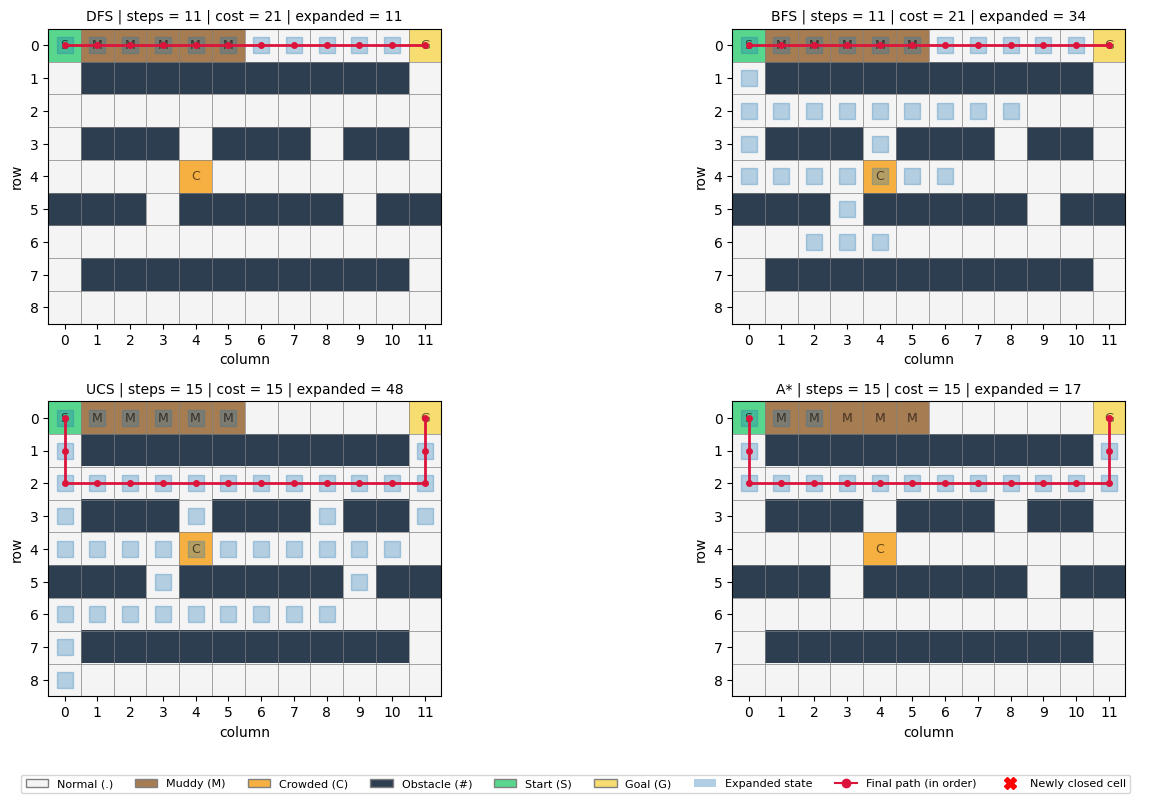

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, alg_name in zip(axes.ravel(), ['DFS', 'BFS', 'UCS', 'A*']):
    res = all_results[('CAMPUS_MAP', alg_name)]
    plot_search_result(CAMPUS_MAP, res, ax=ax, legend=False,
                       title=f"{alg_name} | steps = {res['steps']} | cost = {res['path_cost']} | expanded = {res['nodes_expanded']}")
fig.legend(handles=legend_handles(), loc='lower center', ncol=9, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

### Task 7D - Road closure for roll-number digit 4
Section 2.7: digit **4 or 9** -> close **(2, 10)**. `CLOSED_MAP` is a **deep copy**, so `CAMPUS_MAP` is never changed.

In [ ]:
ROLL_NO = '0054'                                   # <- replace with your full roll number if needed
d = int(ROLL_NO[-1])
CLOSURE_BY_DIGIT = {0: (2, 2), 5: (2, 2), 1: (2, 4), 6: (2, 4), 2: (2, 6), 7: (2, 6),
                    3: (2, 8), 8: (2, 8), 4: (2, 10), 9: (2, 10)}
CLOSED_CELL = CLOSURE_BY_DIGIT[d]
print(f'Roll-number digit d = {d} -> close cell {CLOSED_CELL}')

CLOSED_MAP = copy.deepcopy(CAMPUS_MAP)
CLOSED_MAP[CLOSED_CELL[0]][CLOSED_CELL[1]] = '#'

assert CAMPUS_MAP[CLOSED_CELL[0]][CLOSED_CELL[1]] == '.'          # baseline untouched
assert CLOSED_MAP[CLOSED_CELL[0]][CLOSED_CELL[1]] == '#'
assert CAMPUS_MAP is not CLOSED_MAP and validate_grid(CLOSED_MAP)['valid']

closure_rows, closure_results = [], {}
for label, grid in [('before', CAMPUS_MAP), ('after', CLOSED_MAP)]:
    for alg_name in ['UCS', 'A*']:
        res, runtime_ms = run_experiment(ALGORITHMS[alg_name], grid)
        closure_results[(label, alg_name)] = res
        assert validate_path(grid, res['path'], res['actions'])['valid']
        closure_rows.append({'map': 'CAMPUS_MAP' if label == 'before' else 'CLOSED_MAP', 'closure': label,
                             'algorithm': alg_name, 'goal_reached': res['goal_reached'], 'steps': res['steps'],
                             'path_cost': res['path_cost'], 'nodes_expanded': res['nodes_expanded'],
                             'max_frontier_size': res['max_frontier_size'], 'runtime_ms': round(runtime_ms, 4)})
closure_table = pd.DataFrame(closure_rows)
closure_table

Roll-number digit d = 4 -> close cell (2, 10)


,map,closure,algorithm,goal_reached,steps,path_cost,nodes_expanded,max_frontier_size,runtime_ms
0,CAMPUS_MAP,before,UCS,True,15,15,48,7,0.4311
1,CAMPUS_MAP,before,A*,True,15,15,17,6,0.1911
2,CLOSED_MAP,after,UCS,True,19,19,60,6,0.4913
3,CLOSED_MAP,after,A*,True,19,19,30,6,0.2856


In [ ]:
for alg_name in ['UCS', 'A*']:
    before, after = closure_results[('before', alg_name)], closure_results[('after', alg_name)]
    print(f'{alg_name}: route changed = {before["path"] != after["path"]} | '
          f'cost {before["path_cost"]} -> {after["path_cost"]} | steps {before["steps"]} -> {after["steps"]} | '
          f'expanded {before["nodes_expanded"]} -> {after["nodes_expanded"]}')
print('\nroute after closure (UCS):', closure_results[('after', 'UCS')]['path'])

UCS: route changed = True | cost 15 -> 19 | steps 15 -> 19 | expanded 48 -> 60
A*: route changed = True | cost 15 -> 19 | steps 15 -> 19 | expanded 17 -> 30

route after closure (UCS): [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (3, 8), (4, 8), (4, 9), (4, 10), (4, 11), (3, 11), (2, 11), (1, 11), (0, 11)]


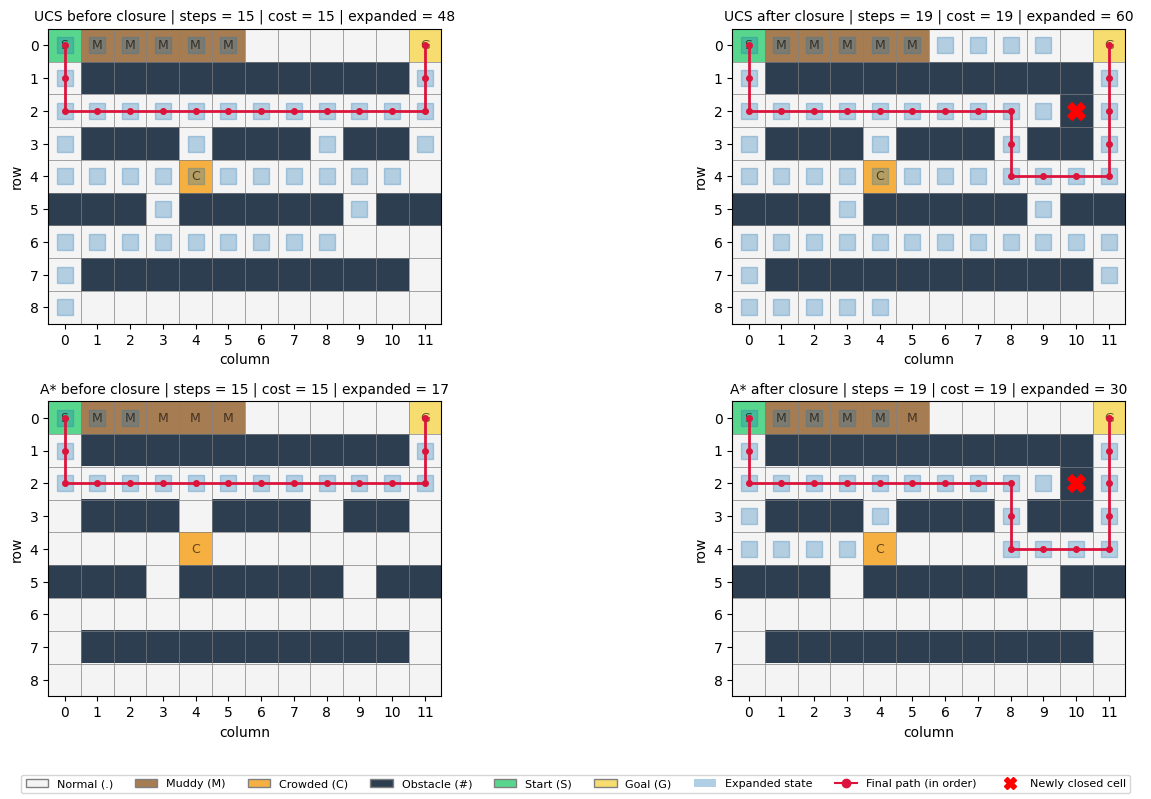

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for row_axes, alg_name in zip(axes, ['UCS', 'A*']):
    for ax, label, grid, blocked in zip(row_axes, ['before', 'after'], [CAMPUS_MAP, CLOSED_MAP], [None, CLOSED_CELL]):
        res = closure_results[(label, alg_name)]
        plot_search_result(grid, res, ax=ax, legend=False, blocked=blocked,
                           title=f"{alg_name} {label} closure | steps = {res['steps']} | cost = {res['path_cost']} "
                                 f"| expanded = {res['nodes_expanded']}")
fig.legend(handles=legend_handles(), loc='lower center', ncol=9, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

**7E - Closure result (digit 4, cell (2, 10)).**
Before the closure, UCS and A\* both used the straight corridor along row 2: 15 steps, cost 15. Closing (2, 10) cuts that corridor, so both algorithms now leave row 2 at column 8, drop to row 4, travel along it to column 11, and climb back up through (3, 11) and (2, 11): **19 steps, cost 19**. The route is 4 steps and 4 cost units longer, still far below the 21-cost muddy route. UCS expanded 48 states before and 60 after; A\* expanded 17 before and 30 after, so A\* still did less work than UCS, but its saving was smaller (the detour makes the straight-line estimate underestimate the true remaining cost by more). I made no extra map, so no additional failure case arises.

### Evidence for Q6 - how stable are runtimes versus node counts?
Each algorithm is run 30 times on `CAMPUS_MAP`; the spread of runtime is shown next to the (constant) node count.

In [ ]:
spread_rows = []
for alg_name, alg in ALGORITHMS.items():
    times = []
    for _ in range(30):
        t0 = perf_counter(); res = alg(CAMPUS_MAP); times.append((perf_counter() - t0) * 1000)
    spread_rows.append({'algorithm': alg_name, 'nodes_expanded (every run)': res['nodes_expanded'],
                        'min_ms': round(min(times), 4), 'median_ms': round(median(times), 4),
                        'max_ms': round(max(times), 4), 'max/min': round(max(times) / min(times), 2)})
pd.DataFrame(spread_rows)

,algorithm,nodes_expanded (every run),min_ms,median_ms,max_ms,max/min
0,DFS,11,0.1037,0.1178,9.5744,92.36
1,BFS,34,0.2164,0.2371,3.6976,17.09
2,UCS,48,0.3143,0.3924,3.4892,11.10
3,A*,17,0.1824,0.1985,2.2924,12.57


In [ ]:
# Evidence for Q8: how often did UCS / A* find a strictly cheaper route to an already-discovered state?
for (map_name, alg_name), res in all_results.items():
    if 'cost_updates' in res:
        print(f'{map_name:20} {alg_name:4} cost_updates = {res["cost_updates"]}')

CAMPUS_MAP           UCS  cost_updates = 0
CAMPUS_MAP           A*   cost_updates = 0
MULTIPLE_ROUTE_MAP   UCS  cost_updates = 0
MULTIPLE_ROUTE_MAP   A*   cost_updates = 0
NO_SOLUTION_MAP      UCS  cost_updates = 0
NO_SOLUTION_MAP      A*   cost_updates = 0


## 9. Interpretation (Section 9.4) - answers use my own results

**Q1. Fewest movements vs least cost on CAMPUS_MAP.** BFS found the fewest-movement route, **11 steps** (cost 21); DFS also returned 11 steps, but only by following the same top corridor without any guarantee. The least-cost route was found by **UCS and A\***, both with **cost 15** (15 steps). So fewer movements (11) did not mean less cost (21 vs 15).

**Q2. Why BFS can be correct yet more expensive.** BFS minimises the *number of actions*, which it does correctly (11 is the minimum). Its route goes through five muddy cells costing 3 each (the muddy top row), giving cost 21. UCS accepts 4 more steps (15) to stay on cost-1 cells and pays only 15. BFS answers a different question from UCS.

**Q3. Did DFS expand fewer nodes than BFS on every map?** No. On CAMPUS_MAP DFS expanded 11 versus BFS 34, and on MULTIPLE_ROUTE_MAP 15 versus 54, but on NO_SOLUTION_MAP both expanded 15 (a tie, not fewer), because with no goal both must explore every reachable state. DFS's count depends heavily on the action order and where the goal lies relative to the first direction it dives; one map cannot establish a universal claim about performance.

**Q4. Do UCS and A\* return the same cost on every solvable map?** Yes: 15 and 15 on CAMPUS_MAP, 15 and 15 on MULTIPLE_ROUTE_MAP, 8 and 8 on MINI_MAP, and 19 and 19 on CLOSED_MAP. All step costs are positive, UCS always pops the cheapest frontier entry, and A\* with an admissible heuristic never overestimates, so the first goal it pops is also optimal; the `h = 0` run also matched UCS.

**Q5. Effect of the Manhattan heuristic.** On CAMPUS_MAP A\* expanded **17** states versus **48** for UCS (about 65% fewer) and its maximum frontier fell from 7 to 6. On MULTIPLE_ROUTE_MAP expansions fell from 54 to 32, but the maximum frontier **rose** from 7 to 11, so the heuristic reduces expansions but does not always reduce frontier size. After the closure expansions were 30 (A\*) versus 60 (UCS).

**Q6. Why runtime is less stable.** The expansion counts are identical in every run (see the Q6 table: constant `nodes_expanded`), but the measured time changes from run to run (see `min_ms`, `median_ms`, `max_ms` and the `max/min` ratio). These searches take only microseconds to a fraction of a millisecond, so operating-system scheduling, caching, Python's garbage collector and timer resolution are comparable in size to the work itself. Node counts are determined by the algorithm and map alone.

**Q7. After the closure (cell (2, 10)).** UCS: cost **15 -> 19**, steps 15 -> 19, nodes expanded **48 -> 60**. A\*: cost 15 -> 19, steps 15 -> 19, nodes expanded **17 -> 30**. The route now detours via row 4 (see Task 7E); both algorithms agree on the new optimum.

**Q8. What changes when UCS/A\* find a cheaper route to an earlier state?** Four things, together: `best_g[state]` is lowered to the new value, `parent[state]` becomes the new predecessor, `action_from_parent[state]` becomes the action from that predecessor, and a **new heap entry** with the lower priority is pushed. The old entry stays in the heap, but when popped its `popped_g` no longer equals `best_g[state]`, so it is skipped as stale and not counted as an expansion. *Observation from my runs:* the `cost_updates` counter was **0** on every map, because here the step cost depends only on the destination cell, so the first route to a state that is generated from the lowest-g popped neighbour is already the cheapest. The rule is still required for general costs and is implemented, but I could not trigger it on these maps.

**Q9. Evidence that NO_SOLUTION_MAP was handled correctly.** All four algorithms returned `goal_reached = False`, empty `path` and `actions`, and `steps = path_cost = None`. Each also reports **15 nodes expanded**, which equals every cell in the three left-hand columns (5 rows x 3 columns) that can be reached from S, so none gave up early: they exhausted the frontier. Max frontier size was 5 for DFS and 3 for BFS, UCS and A\*, and the assertions confirm termination.

**Q10. Recommendation.** For a campus with reliable terrain costs I would use **A\*** with the Manhattan heuristic: it returned the same optimal cost as UCS (15) while expanding far fewer states (17 vs 48 on CAMPUS_MAP). BFS is still reasonable when every move costs the same or when only the number of movements matters (for example equal-cost corridors), since it then guarantees the optimum with simple code.

## 10. Reproducibility check
 *"I restarted the runtime and selected Run all. Every cell executed in order without manual variable repair, hidden state or local file paths."*



In [ ]:
# Final reproducibility check: re-run all algorithms and confirm identical results
again = {(m, a): ALGORITHMS[a](EXPERIMENT_MAPS[m]) for (m, a) in all_results}
assert again == all_results
assert CAMPUS_MAP == copy.deepcopy(CAMPUS_MAP) and CAMPUS_MAP[2][10] == '.'
print('Reproducibility check: PASS (results identical on re-run; baseline map unchanged)')

Reproducibility check: PASS (results identical on re-run; baseline map unchanged)
